# BT4012 Fraud Analytics Group 14: RGCN

## Loading libraries

In [1]:
from pathlib import Path
import platform
import time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve, confusion_matrix
from sklearn.preprocessing import RobustScaler

## Configuration

In [2]:
ROOT = Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
GRAPH_DIR = PROCESSED / "graph"
OUT_DIR = ROOT / "results"

DROP_RELATIONS = ["shared_related_org"]
KEEP_RELATIONS = ["related_party_transaction", "shared_related_unlisted_firm", "org_investor_and_related_party", "unlisted_investment_and_related_party"]
CLIP = None
RGCN_KW = dict(n_layers=2, skip=True)

HIDDEN = 64
DROPOUT = 0.3
LR = 0.005
WEIGHT_DECAY = 5e-4
MAX_EPOCHS = 300
PATIENCE = 30
SEED = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Hardware

In [3]:
torch.set_num_threads(8)

print(f"python {platform.python_version()} | torch {torch.__version__} | CUDA build {torch.version.cuda}")

if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"running on {props.name}, {props.total_memory / 1e9:.1f} GB")
else:
    print("WARNING: CUDA not available, running on CPU")

python 3.12.16 | torch 2.14.0+cu132 | CUDA build 13.2
running on NVIDIA GeForce RTX 4060 Laptop GPU, 8.6 GB


## Splits, relations and feature blocks

In [4]:
splits = pd.read_csv(ROOT / "data" / "splits" / "temporal_splits.csv")
split_test_year = (splits[splits["role"] == "test"].groupby("split")["Year"].first().astype(int).to_dict())
TEST_YEARS = list(split_test_year.values())

all_relations = (pq.read_table(GRAPH_DIR / "company_edges.parquet", columns=["relation"]).column("relation").unique().to_pylist())
RELATIONS = sorted(r for r in all_relations if r not in DROP_RELATIONS)

feature_cols = pd.read_csv(GRAPH_DIR / "feature_cols.csv")["feature"].tolist()
text_cols = set()
for path in [PROCESSED / "text_features.parquet", PROCESSED / "text_embeddings.parquet", PROCESSED / "text_tfidf" / "split_0.parquet"]:
    text_cols |= set(pq.read_schema(path).names)
degree_cols = set(pd.read_csv(GRAPH_DIR / "degree_features.csv", nrows=0).columns)
BLOCK = np.array(["text" if c in text_cols else "degree" if c in degree_cols else "tabular" for c in feature_cols])
KEEP_RELATIONS = RELATIONS

print("test year per split:", split_test_year)
print(f"relations ({len(RELATIONS)}):", ", ".join(RELATIONS))
print(f"features ({len(feature_cols):,}):", pd.Series(BLOCK).value_counts().to_dict())

test year per split: {0: 2019, 1: 2020, 2: 2021, 3: 2022}
relations (12): Investment, individual_investor_and_related_party, org_investor_and_related_party, related_party_transaction, shared_auditor, shared_individual_investor, shared_org_investor, shared_related_individual, shared_related_unlisted_firm, shared_unlisted_investment, supply_chain_partner, unlisted_investment_and_related_party
features (1,414): {'tabular': 1238, 'text': 172, 'degree': 4}


## Data loading

In [5]:
def load_split(s: int):
    graphs = torch.load(GRAPH_DIR / f"graphs_split_{s}.pt", weights_only=False)
    xs, ids, years, labels, edge_index, edge_type = [], [], [], [], [], []
    offset = 0
    for yr in sorted(graphs):
        g = graphs[yr]
        xs.append(g.x)
        ids += list(g.node_ids)
        years.append(np.full(g.num_nodes, yr))
        labels.append(g.y.numpy())
        edge_index.append(g.edge_index + offset)
        edge_type.append(g.edge_type)
        offset += g.num_nodes

    nodes = pd.DataFrame({"nodeID": ids, "Year": np.concatenate(years), "Label": np.concatenate(labels)})
    X = torch.cat(xs).numpy()
    edge_index, edge_type = torch.cat(edge_index, dim=1), torch.cat(edge_type)

    expected = splits[splits["split"] == s]
    check = nodes.merge(expected, on=["nodeID", "Year"], how="left", suffixes=("", "_splits"))
    assert len(nodes) == len(expected), f"split {s}: node count differs from temporal_splits.csv"
    assert (check["Label"] == check["Label_splits"]).all(), f"split {s}: labels differ from temporal_splits.csv"
    assert nodes["Year"].max() == split_test_year[s], f"split {s}: last graph is not the test year"
    assert X.shape[1] == len(feature_cols), f"split {s}: feature count differs from feature_cols.csv"
    assert np.isfinite(X).all(), f"split {s}: features contain NaN or inf"
    assert int(edge_type.max()) < len(RELATIONS), "edge_type out of range; check DROP_RELATIONS"
    return nodes, X, edge_index, edge_type

def build_adjacency(edge_index, edge_type, n: int) -> list[torch.Tensor]:
    src, dst = edge_index
    adjs = []
    for r in range(len(RELATIONS)):
        m = edge_type == r
        i, j = dst[m], src[m]
        deg = torch.bincount(i, minlength=n).clamp(min=1).float()
        A = torch.sparse_coo_tensor(torch.stack([i, j]), 1.0 / deg[i], (n, n), check_invariants=False)
        adjs.append(A.coalesce().to(DEVICE))
    return adjs

def prepare_inputs(X: np.ndarray, fit_rows: np.ndarray) -> tuple[np.ndarray, dict]:
    X = X.copy()
    text = BLOCK == "text"
    X[:, text] = RobustScaler().fit(X[fit_rows][:, text]).transform(X[:, text])
    X = np.sign(X) * np.log1p(np.abs(X))

    clipped = {}
    if CLIP is not None:
        beyond = np.abs(X) > CLIP
        clipped = {b: float(beyond[:, BLOCK == b].mean()) for b in ("tabular", "text", "degree")}
        X = np.clip(X, -CLIP, CLIP)
    return X.astype(np.float32), clipped

def add_fraud_history(nodes: pd.DataFrame, X: np.ndarray) -> np.ndarray:
    """Append two columns: was this company fraud the year before (0 if not listed then),
    and was it listed the year before. Only labels from earlier years are used."""
    prev = (nodes[["nodeID", "Year", "Label"]]
            .assign(Year=nodes["Year"] + 1)
            .rename(columns={"Label": "prev_fraud"}))
    m = nodes[["nodeID", "Year"]].merge(prev, on=["nodeID", "Year"], how="left", validate="one_to_one")
    prev_fraud = m["prev_fraud"].fillna(0).to_numpy(np.float32)
    had_prev_year = m["prev_fraud"].notna().to_numpy(np.float32)
    return np.column_stack([X, prev_fraud, had_prev_year]).astype(np.float32)

## Model

In [6]:
class RGCNLayer(nn.Module):
    def __init__(self, d_in: int, d_out: int, n_rel: int):
        super().__init__()
        self.self_lin = nn.Linear(d_in, d_out)
        self.rel_lin = nn.ModuleList(nn.Linear(d_in, d_out, bias=False) for _ in range(n_rel))

    def forward(self, h, adjs):
        out = self.self_lin(h)
        for A, lin in zip(adjs, self.rel_lin):
            out = out + torch.sparse.mm(A, lin(h))
        return out

class RGCN(nn.Module):
    def __init__(self, d_in: int, n_rel: int, n_layers: int = 2, skip: bool = False):
        super().__init__()
        self.inp = nn.Linear(d_in, HIDDEN)
        self.convs = nn.ModuleList(RGCNLayer(HIDDEN, HIDDEN, n_rel) for _ in range(n_layers))
        self.skip = skip
        self.out = nn.Linear(HIDDEN * (n_layers + 1) if skip else HIDDEN, 1)
        self.drop = nn.Dropout(DROPOUT)

    def embed(self, x, adjs):
        h = self.drop(F.relu(self.inp(x)))
        hs = [h]
        for conv in self.convs:
            h = self.drop(F.relu(conv(h, adjs)))
            hs.append(h)
        return torch.cat(hs, dim=1) if self.skip else h

    def forward(self, x, adjs):
        return self.out(self.embed(x, adjs)).squeeze(1)

## Training

In [7]:
def scores(y, p):
    return roc_auc_score(y, p), average_precision_score(y, p)

def train_one(X, y, adjs, tr, va, n_rel, return_model=False, **model_kw):
    torch.manual_seed(SEED)
    model = RGCN(X.shape[1], n_rel, **model_kw).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    pos_weight = (y[tr] == 0).sum() / (y[tr] == 1).sum()
    y_np = y.cpu().numpy()
    
    history = []
    best_auc, best_state, best_epoch, waited = -1.0, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        opt.zero_grad()
        logits = model(X, adjs)
        loss = F.binary_cross_entropy_with_logits(logits[tr], y[tr], pos_weight=pos_weight)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            p = torch.sigmoid(model(X, adjs)).cpu().numpy()
        val_auc = roc_auc_score(y_np[va.cpu().numpy()], p[va.cpu().numpy()])
        history.append({"epoch": epoch, "loss": loss.item(), "val_auc": val_auc})
        if val_auc > best_auc:
            best_auc, best_epoch, waited = val_auc, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= PATIENCE:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(X, adjs)).cpu().numpy()
    hist = pd.DataFrame(history)
    return (p, best_auc, best_epoch, hist, model) if return_model else (p, best_auc, best_epoch, hist)

In [8]:
emb = {}
for s, test_year in split_test_year.items():
    val_year = test_year - 1
    nodes, X_np, edge_index, edge_type = load_split(s)
    year, labels = nodes["Year"].to_numpy(), nodes["Label"].to_numpy()
    X_np, _ = prepare_inputs(X_np, fit_rows=year < test_year)
    X_np = X_np[:, ~np.array([c.endswith(("_yoy", "_was_missing")) for c in feature_cols])]
    X_t = torch.tensor(add_fraud_history(nodes, X_np), device=DEVICE)
    adjs = build_adjacency(edge_index, edge_type, len(nodes))
    y_t = torch.tensor(labels, dtype=torch.float32, device=DEVICE)
    tr, va = (torch.tensor(m, device=DEVICE) for m in (year < val_year, year == val_year))

    p, val_auc, epoch, _, model = train_one(X_t, y_t, adjs, tr, va, len(adjs), return_model=True, **RGCN_KW)
    model.eval()
    with torch.no_grad():
        H = model.embed(X_t, adjs).cpu().numpy()

    emb[s] = {"H": H, "nodeID": nodes["nodeID"].to_numpy(), "year": year, "labels": labels, "p": p, "model": model}
    test = year == test_year
    print(f"split {s} ({test_year}): H {H.shape}, RGCN test AUC {roc_auc_score(labels[test], p[test]):.4f}")

    del X_t, y_t, adjs, tr, va  # free GPU memory before the next split
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

c:\Users\iiank-laptop\anaconda3\envs\bt4012\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\iiank-laptop\anaconda3\envs\bt4012\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


split 0 (2019): H (19494, 192), RGCN test AUC 0.8670
split 1 (2020): H (23763, 192), RGCN test AUC 0.8330
split 2 (2021): H (28532, 192), RGCN test AUC 0.8347
split 3 (2022): H (33664, 192), RGCN test AUC 0.8944


In [9]:
EMB_DIR = PROCESSED / "rgcn_embeddings"
EMB_DIR.mkdir(parents=True, exist_ok=True)
for s, e in emb.items():
    val_year = split_test_year[s] - 1
    info = pd.DataFrame({"nodeID": e["nodeID"],
                         "Year": e["year"],
                         "Label": e["labels"],
                         "role": np.select([e["year"] < val_year, e["year"] == val_year], ["train", "val"], "test"),
                         "rgcn_score": e["p"]})
    vecs = pd.DataFrame(e["H"], columns=[f"h{i}" for i in range(e["H"].shape[1])])
    pd.concat([info, vecs], axis=1).to_parquet(EMB_DIR / f"split_{s}.parquet", index=False)
    print(f"saved split {s}: {len(info):,} rows, {e['H'].shape[1]} hidden columns")

saved split 0: 19,494 rows, 192 hidden columns
saved split 1: 23,763 rows, 192 hidden columns
saved split 2: 28,532 rows, 192 hidden columns
saved split 3: 33,664 rows, 192 hidden columns


## Walk-forward experiments

In [10]:
rows, preds, histories, split_info = [], [], [], []
for s, test_year in split_test_year.items():
    val_year = test_year - 1
    nodes, X, edge_index, edge_type = load_split(s)
    year = nodes["Year"].to_numpy()
    labels = nodes["Label"].to_numpy()
    test_mask = year == test_year

    X, clipped = prepare_inputs(X, fit_rows=year < test_year)
    X = X[:, ~np.array([c.endswith(("_yoy", "_was_missing")) for c in feature_cols])]
    X = add_fraud_history(nodes, X)
    adjs = build_adjacency(edge_index, edge_type, len(nodes))
    adjs = [adjs[RELATIONS.index(r)] for r in KEEP_RELATIONS]
    n_edges = sum(A._nnz() for A in adjs)
    X = torch.tensor(X, device=DEVICE)
    y = torch.tensor(labels, dtype=torch.float32, device=DEVICE)
    tr, va = (torch.tensor(m, device=DEVICE) for m in (year < val_year, year == val_year))

    split_info.append({"split": s,
                       "test_year": test_year,
                       "nodes": len(nodes),
                       "edges": n_edges,
                       "features": X.shape[1],
                       "train_fraud": int(labels[year < val_year].sum()),
                       "val_fraud": int(labels[year == val_year].sum()),
                       "test_fraud": int(labels[test_mask].sum()),
                       **{f"clipped_{b}": v for b, v in clipped.items()}})
    print(f"split {s}: {len(nodes):,} nodes, {n_edges:,} edges, {X.shape[1]:,} features; "
          "values clipped: " + ", ".join(f"{b} {v:.2%}" for b, v in clipped.items()))

    p_by_model = {}
    for name, graph, kw in [("mlp", [], {}), ("rgcn", adjs, RGCN_KW)]:
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        t0 = time.perf_counter()
        p, val_auc, epoch, hist = train_one(X, y, graph, tr, va, len(graph), **kw)
        p_by_model[name] = p
        secs = time.perf_counter() - t0
        gpu_gb = torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else np.nan

        auc, ap = scores(labels[test_mask], p[test_mask])
        rows.append({"model": name,
                     "split": s,
                     "test_year": test_year,
                     "best_epoch": epoch,
                     "val_auc": val_auc,
                     "test_auc": auc,
                     "test_pr_auc": ap,
                     "test_fraud_rate": labels[test_mask].mean(),
                     "seconds": secs,
                     "peak_gpu_gb": gpu_gb})
        preds.append(nodes.loc[test_mask, ["nodeID", "Year", "Label"]].assign(model=name, score=p[test_mask]))
        histories.append(hist.assign(model=name, test_year=test_year))
        print(f"  {name:<5} {test_year}  epoch {epoch:>3}  val {val_auc:.4f}  "
              f"test AUC {auc:.4f}  PR-AUC {ap:.4f}  {secs:.0f}s  {gpu_gb:.2f} GB")

    # ensemble: the average of the MLP's and the RGCN's scores
    p = (p_by_model["mlp"] + p_by_model["rgcn"]) / 2
    val_mask = year == val_year
    auc, ap = scores(labels[test_mask], p[test_mask])
    rows.append({"model": "ens",
                 "split": s,
                 "test_year": test_year,
                 "best_epoch": np.nan,
                 "val_auc": roc_auc_score(labels[val_mask], p[val_mask]),
                 "test_auc": auc,
                 "test_pr_auc": ap,
                 "test_fraud_rate": labels[test_mask].mean(),
                 "seconds": np.nan,
                 "peak_gpu_gb": np.nan})
    preds.append(nodes.loc[test_mask, ["nodeID", "Year", "Label"]].assign(model="ens", score=p[test_mask]))
    print(f"  {'ens':<5} {test_year}  test AUC {auc:.4f}  PR-AUC {ap:.4f}")
    del X, y, adjs, tr, va  # free GPU memory before the next split
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

res = pd.DataFrame(rows).round(4)
preds_df = pd.concat(preds, ignore_index=True)
hist_df = pd.concat(histories, ignore_index=True)
split_info = pd.DataFrame(split_info)
print()
print(res.groupby("model")[["test_auc", "test_pr_auc"]].mean())

OUT_DIR.mkdir(exist_ok=True)
res.to_csv(OUT_DIR / "rgcn_results.csv", index=False)
preds_df.to_csv(OUT_DIR / "rgcn_predictions.csv", index=False)
res

split 0: 19,494 nodes, 7,802,746 edges, 729 features; values clipped: 
  mlp   2019  epoch  95  val 0.9026  test AUC 0.8774  PR-AUC 0.3519  1s  0.28 GB
  rgcn  2019  epoch  70  val 0.8870  test AUC 0.8580  PR-AUC 0.3605  10s  0.58 GB
  ens   2019  test AUC 0.8809  PR-AUC 0.3962
split 1: 23,763 nodes, 9,345,718 edges, 729 features; values clipped: 
  mlp   2020  epoch 111  val 0.9065  test AUC 0.8400  PR-AUC 0.3769  1s  0.33 GB
  rgcn  2020  epoch  56  val 0.8920  test AUC 0.8312  PR-AUC 0.3043  11s  0.70 GB
  ens   2020  test AUC 0.8397  PR-AUC 0.3635
split 2: 28,532 nodes, 11,163,822 edges, 729 features; values clipped: 
  mlp   2021  epoch  29  val 0.8618  test AUC 0.7989  PR-AUC 0.2186  1s  0.39 GB
  rgcn  2021  epoch  58  val 0.8711  test AUC 0.8365  PR-AUC 0.2809  13s  0.87 GB
  ens   2021  test AUC 0.8165  PR-AUC 0.2531
split 3: 33,664 nodes, 13,157,604 edges, 729 features; values clipped: 
  mlp   2022  epoch 116  val 0.8864  test AUC 0.8913  PR-AUC 0.3319  1s  0.46 GB
  rgcn  2

,model,split,test_year,best_epoch,val_auc,test_auc,test_pr_auc,test_fraud_rate,seconds,peak_gpu_gb
0,mlp,0,2019,95.0,0.9026,0.8774,0.3519,0.0561,1.1042,0.2769
1,rgcn,0,2019,70.0,0.8870,0.8580,0.3605,0.0561,10.4446,0.5764
2,ens,0,2019,NaN,0.9023,0.8809,0.3962,0.0561,NaN,NaN
3,mlp,1,2020,111.0,0.9065,0.8400,0.3769,0.0485,1.1642,0.3285
4,rgcn,1,2020,56.0,0.8920,0.8312,0.3043,0.0485,10.6594,0.7049
5,ens,1,2020,NaN,0.9042,0.8397,0.3635,0.0485,NaN,NaN
6,mlp,2,2021,29.0,0.8618,0.7989,0.2186,0.0384,0.6437,0.3908
7,rgcn,2,2021,58.0,0.8711,0.8365,0.2809,0.0384,12.9490,0.8664
8,ens,2,2021,NaN,0.8722,0.8165,0.2531,0.0384,NaN,NaN
9,mlp,3,2022,116.0,0.8864,0.8913,0.3319,0.0240,1.3653,0.4562


### Split summary

In [11]:
split_info

,split,test_year,nodes,edges,features,train_fraud,val_fraud,test_fraud
0,0,2019,19494,7802746,729,607,225,214
1,1,2020,23763,9345718,729,832,214,207
2,2,2021,28532,11163822,729,1046,207,183
3,3,2022,33664,13157604,729,1253,183,123


## Visualising the metrics

In [12]:
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["mlp", "rgcn", "ens"]
TRAINED = ["mlp", "rgcn"] 
COLORS = {"mlp": "#2a78d6", "rgcn": "#eb6834", "ens": "#1baf7a"}
NAMES = {"mlp": "MLP (no graph)", "rgcn": "RGCN", "ens": "MLP + RGCN"}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "lines.linewidth": 2,
    "font.size": 10,
    "axes.titlesize": 11,
    "legend.frameon": False,
})

def baseline(ax, x, y, label):
    ax.plot(x, y, ls="--", lw=1.2, color=MUTED, label=label)

def subset(model, yr):
    return preds_df[(preds_df["model"] == model) & (preds_df["Year"] == yr)]

### Headline metrics per test year

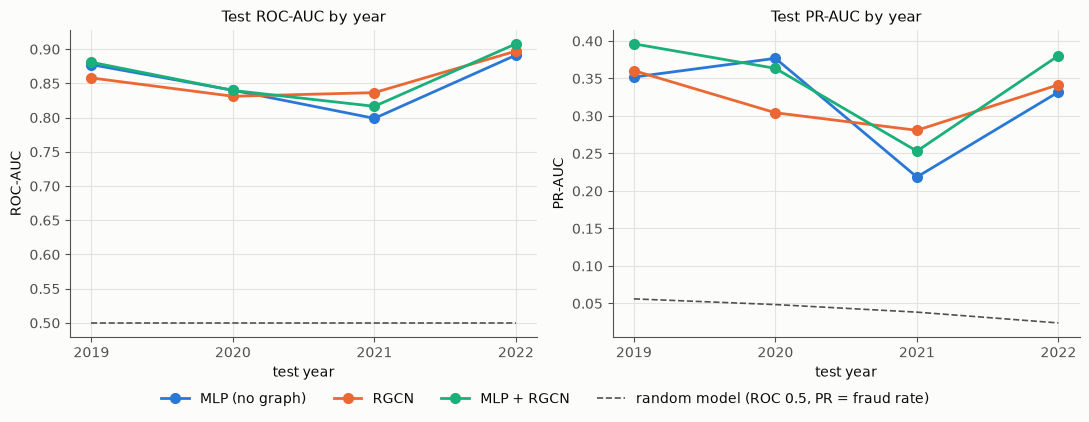

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rate = res[res["model"] == "mlp"].sort_values("test_year")
for ax, metric, title in [(axes[0], "test_auc", "ROC-AUC"), (axes[1], "test_pr_auc", "PR-AUC")]:
    for m in MODELS:
        d = res[res["model"] == m].sort_values("test_year")
        ax.plot(d["test_year"], d[metric], marker="o", ms=7, color=COLORS[m], label=NAMES[m])
    if metric == "test_auc":
        baseline(ax, rate["test_year"], [0.5] * len(rate), "random model")
    else:
        baseline(ax, rate["test_year"], rate["test_fraud_rate"], "random model")
    ax.set(title=f"Test {title} by year", xlabel="test year", ylabel=title, xticks=TEST_YEARS)
handles, names = axes[0].get_legend_handles_labels()
names[-1] = "random model (ROC 0.5, PR = fraud rate)"
fig.legend(handles, names, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
fig.savefig(FIG_DIR / "metrics_by_year.png", dpi=200, bbox_inches="tight")
plt.show()

### ROC and precision-recall curves

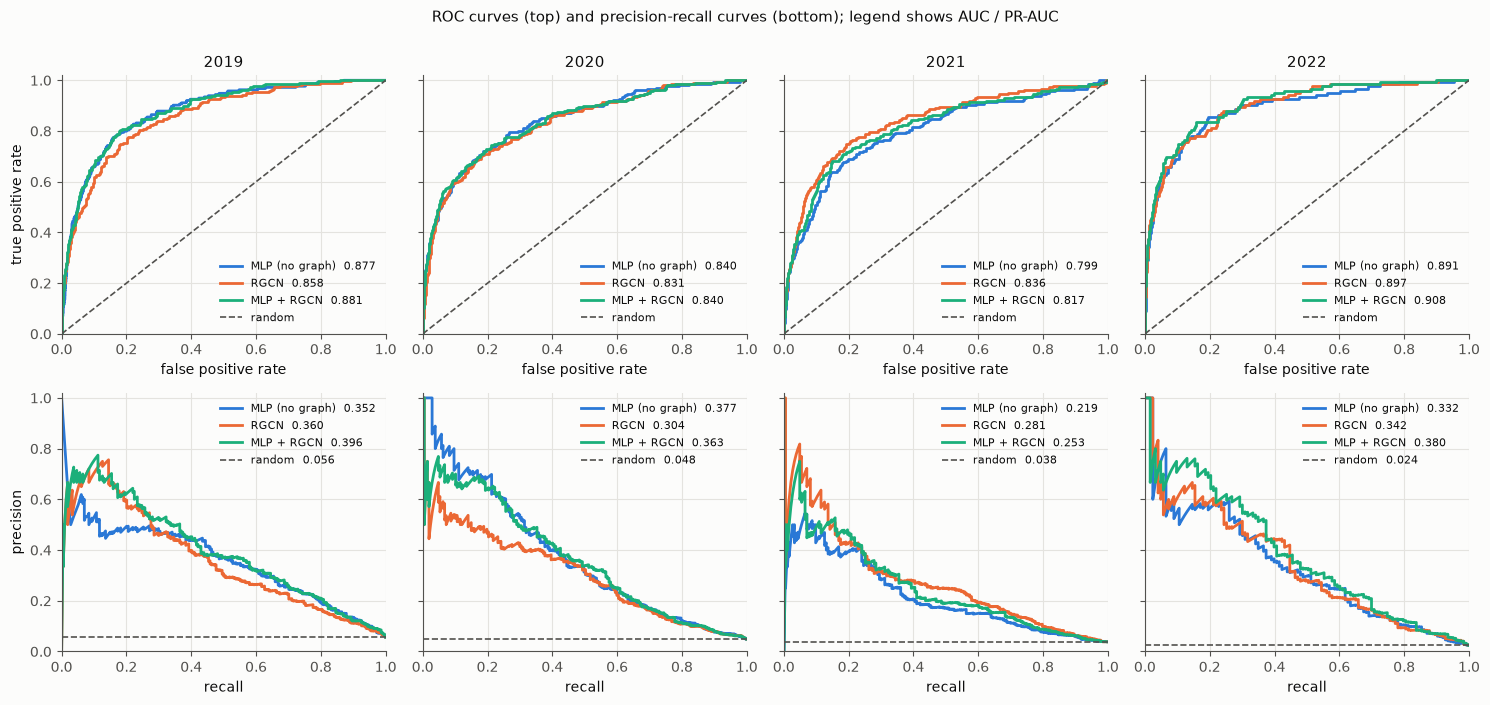

In [14]:
fig, axes = plt.subplots(2, len(TEST_YEARS), figsize=(15, 7), sharex=True, sharey="row")
for col, yr in enumerate(TEST_YEARS):
    roc_ax, pr_ax = axes[0, col], axes[1, col]
    for m in MODELS:
        g = subset(m, yr)
        fpr, tpr, _ = roc_curve(g["Label"], g["score"])
        prec, rec, _ = precision_recall_curve(g["Label"], g["score"])
        auc, ap = scores(g["Label"], g["score"])
        roc_ax.plot(fpr, tpr, color=COLORS[m], label=f"{NAMES[m]}  {auc:.3f}")
        pr_ax.plot(rec, prec, color=COLORS[m], label=f"{NAMES[m]}  {ap:.3f}")
    rate_yr = g["Label"].mean()
    baseline(roc_ax, [0, 1], [0, 1], "random")
    baseline(pr_ax, [0, 1], [rate_yr, rate_yr], f"random  {rate_yr:.3f}")
    roc_ax.set(title=str(yr), xlim=(0, 1), ylim=(0, 1.02), xlabel="false positive rate")
    roc_ax.xaxis.set_tick_params(labelbottom=True)
    pr_ax.set(xlabel="recall", ylim=(0, 1.02))
    roc_ax.legend(fontsize=8, loc="lower right")
    pr_ax.legend(fontsize=8, loc="upper right")
axes[0, 0].set_ylabel("true positive rate")
axes[1, 0].set_ylabel("precision")
fig.suptitle("ROC curves (top) and precision-recall curves (bottom); legend shows AUC / PR-AUC", y=1.0, fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "roc_pr_curves.png", dpi=200, bbox_inches="tight")
plt.show()

### Frauds caught when reviewing the top-scored companies

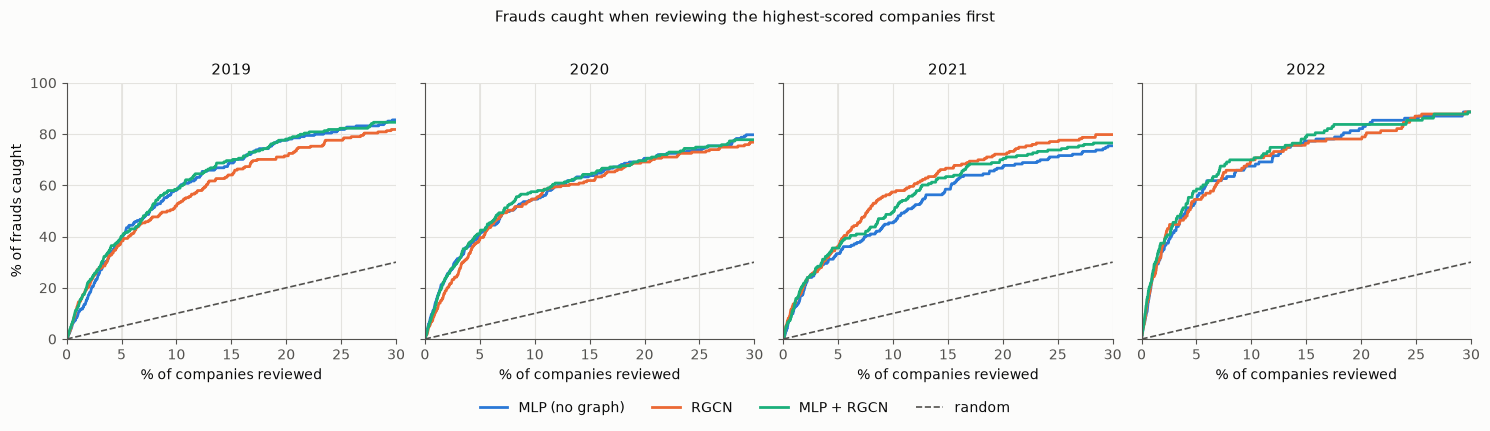

In [15]:
fig, axes = plt.subplots(1, len(TEST_YEARS), figsize=(15, 3.8), sharey=True)
for ax, yr in zip(axes, TEST_YEARS):
    for m in MODELS:
        y_sorted = subset(m, yr).sort_values("score", ascending=False)["Label"].to_numpy()
        reviewed = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
        ax.plot(reviewed * 100, np.cumsum(y_sorted) / y_sorted.sum() * 100, color=COLORS[m], label=NAMES[m])
    baseline(ax, [0, 30], [0, 30], "random")
    ax.axvline(5, color=GRID, lw=1.2, zorder=0)
    ax.set(title=str(yr), xlim=(0, 30), ylim=(0, 100), xlabel="% of companies reviewed")
axes[0].set_ylabel("% of frauds caught")
handles, names = axes[0].get_legend_handles_labels()
fig.suptitle("Frauds caught when reviewing the highest-scored companies first", y=1.02, fontsize=11)
fig.tight_layout()
fig.legend(handles, names, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.08))
fig.savefig(FIG_DIR / "capture_curves.png", dpi=200, bbox_inches="tight")
plt.show()

### Precision and recall at the top 1%, 5% and 10%

In [16]:
rows_k = []
for (m, yr), g in preds_df.groupby(["model", "Year"]):
    g = g.sort_values("score", ascending=False)
    for k in (0.01, 0.05, 0.10):
        top = g.head(int(np.ceil(k * len(g))))
        rows_k.append({"model": NAMES[m],
                       "test_year": yr,
                       "top_%_reviewed": int(k * 100),
                       "precision": top["Label"].mean(),
                       "recall": top["Label"].sum() / g["Label"].sum()})
topk = (pd.DataFrame(rows_k)
        .pivot_table(index=["top_%_reviewed", "test_year"], columns="model", values=["precision", "recall"])
        .round(3))
topk.to_csv(OUT_DIR / "topk_precision_recall.csv")
topk

precision                           recall  \
model                    MLP (no graph) MLP + RGCN   RGCN MLP (no graph)   
top_%_reviewed test_year                                                   
1              2019               0.513      0.692  0.744          0.093   
               2020               0.698      0.651  0.512          0.145   
               2021               0.458      0.500  0.521          0.120   
               2022               0.577      0.596  0.558          0.244   
5              2019               0.440      0.450  0.429          0.393   
               2020               0.397      0.402  0.379          0.411   
               2021               0.255      0.272  0.276          0.333   
               2022               0.261      0.280  0.261          0.545   
10             2019               0.327      0.327  0.291          0.584   
               2020               0.265      0.279  0.265          0.546   
               2021               0.174      0.191  0.220          0.454   
               2022               0.161      0.167  0.167          0.675   

                                            
model                    MLP + RGCN   RGCN  
top_%_reviewed test_year                    
1              2019           0.126  0.136  
               2020           0.135  0.106  
               2021           0.131  0.137  
               2022           0.252  0.236  
5              2019           0.402  0.383  
               2020           0.415  0.391  
               2021           0.355  0.361  
               2022           0.585  0.545  
10             2019           0.584  0.519  
               2020           0.575  0.546  
               2021           0.497  0.574  
               2022           0.699  0.699

### Training curves

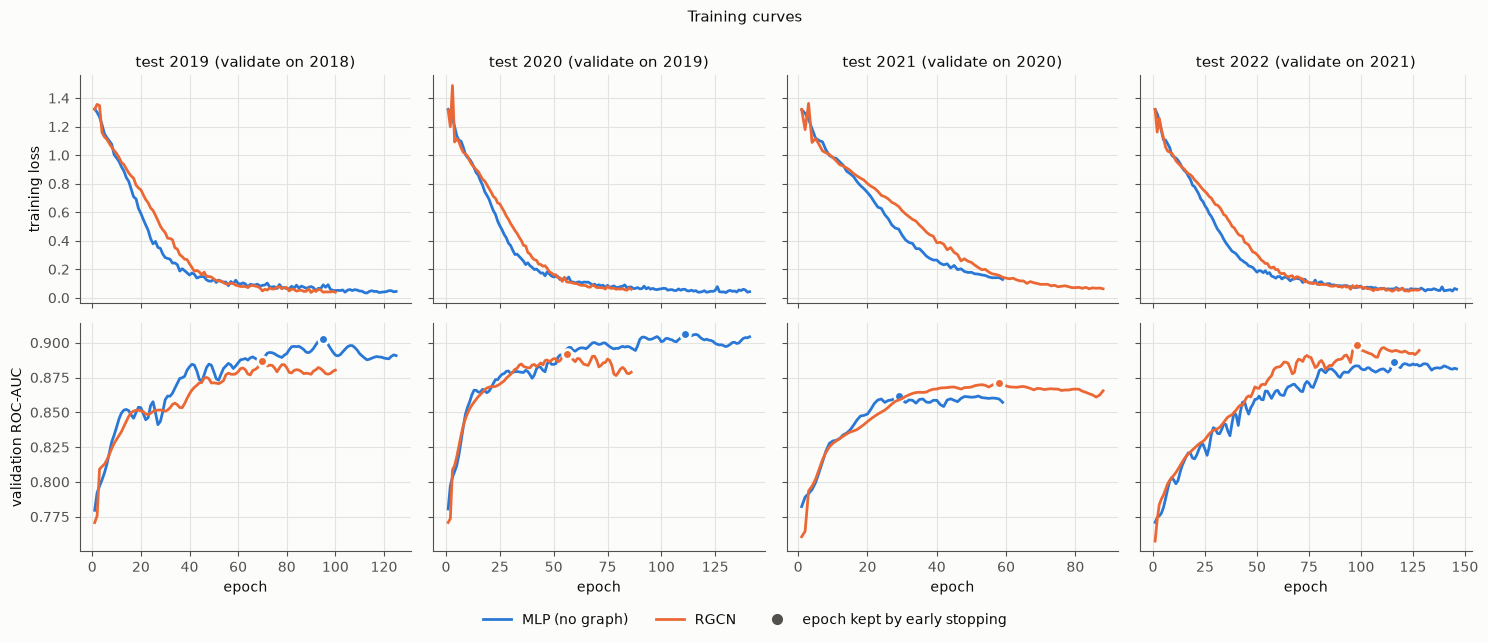

In [17]:
fig, axes = plt.subplots(2, len(TEST_YEARS), figsize=(15, 6), sharex="col", sharey="row")
for col, yr in enumerate(TEST_YEARS):
    for m in TRAINED:
        h = hist_df[(hist_df["model"] == m) & (hist_df["test_year"] == yr)]
        best = h.loc[h["val_auc"].idxmax()]
        axes[0, col].plot(h["epoch"], h["loss"], color=COLORS[m])
        axes[1, col].plot(h["epoch"], h["val_auc"], color=COLORS[m])
        axes[1, col].plot(best["epoch"], best["val_auc"], "o", ms=7, color=COLORS[m], markeredgecolor=SURFACE, markeredgewidth=2)
    axes[0, col].set_title(f"test {yr} (validate on {yr - 1})")
    axes[1, col].set_xlabel("epoch")
axes[0, 0].set_ylabel("training loss")
axes[1, 0].set_ylabel("validation ROC-AUC")

handles = [Line2D([], [], color=COLORS[m], label=NAMES[m]) for m in TRAINED]
handles.append(Line2D([], [], ls="", marker="o", ms=7, color=MUTED, label="epoch kept by early stopping"))
fig.suptitle("Training curves", y=1.0, fontsize=11)
fig.tight_layout()
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.05))
fig.savefig(FIG_DIR / "training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

### Confusion matrices

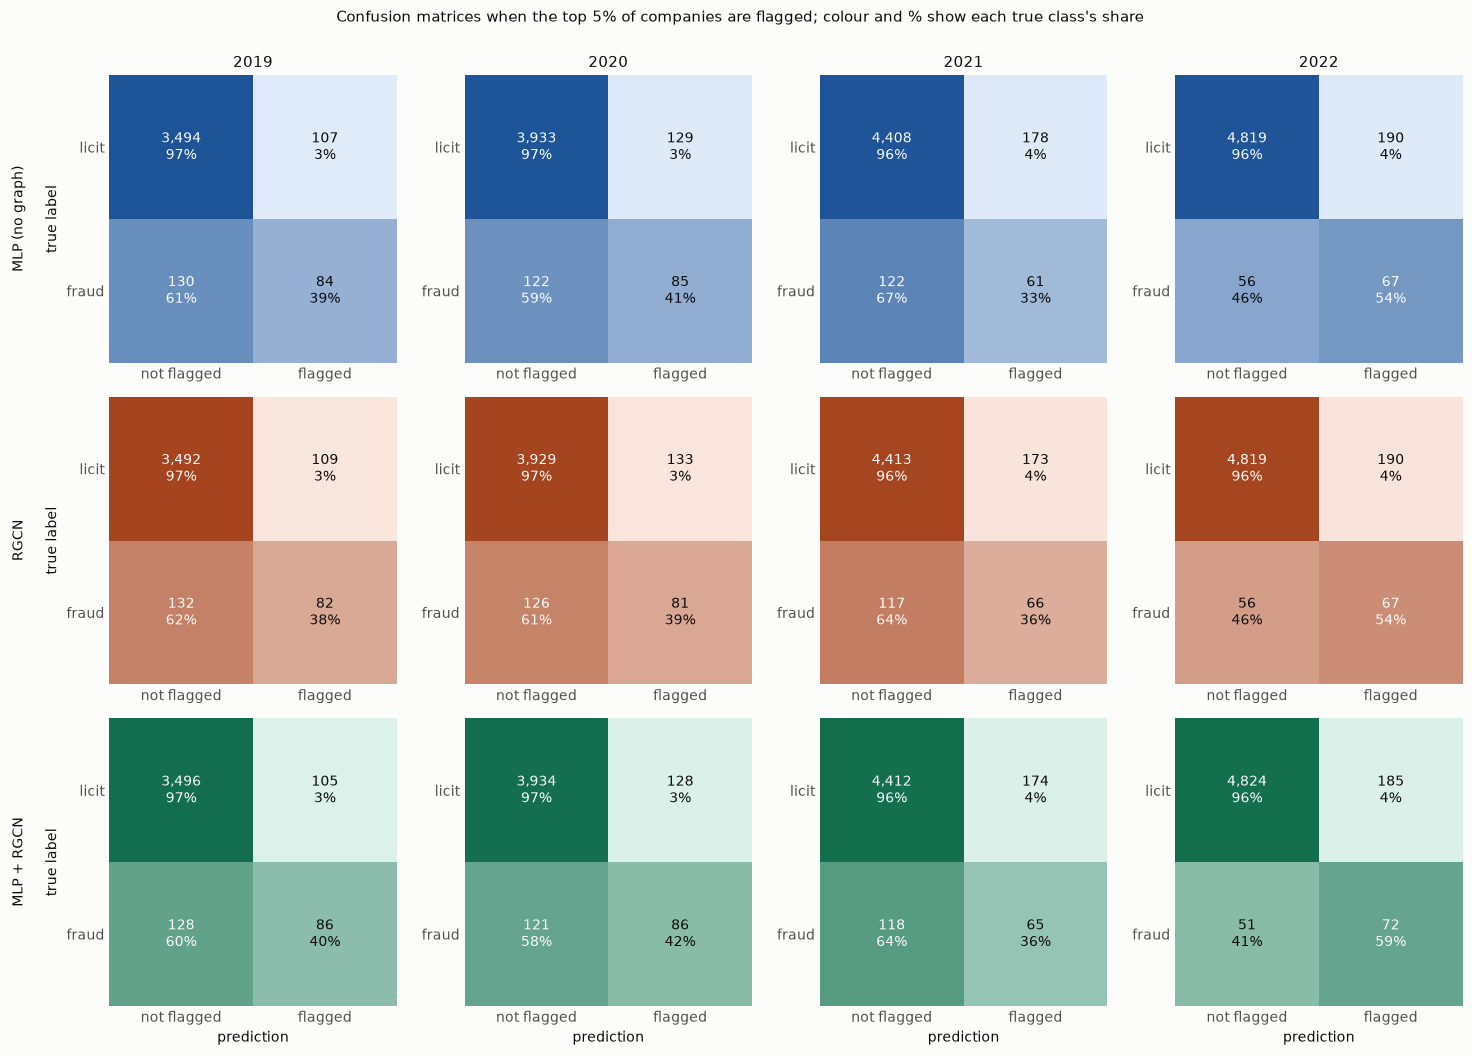

,model,test_year,TP,FP,FN,TN,precision,recall
0,MLP (no graph),2019,84,107,130,3494,0.440,0.393
1,MLP (no graph),2020,85,129,122,3933,0.397,0.411
2,MLP (no graph),2021,61,178,122,4408,0.255,0.333
3,MLP (no graph),2022,67,190,56,4819,0.261,0.545
4,RGCN,2019,82,109,132,3492,0.429,0.383
5,RGCN,2020,81,133,126,3929,0.379,0.391
6,RGCN,2021,66,173,117,4413,0.276,0.361
7,RGCN,2022,67,190,56,4819,0.261,0.545
8,MLP + RGCN,2019,86,105,128,3496,0.450,0.402
9,MLP + RGCN,2020,86,128,121,3934,0.402,0.415


In [18]:
FLAG_SHARE = 0.05
RAMPS = {"mlp": ["#e6f0fc", "#184f95"], "rgcn": ["#fcebe3", "#a3401a"], "ens": ["#e2f5ee", "#0d6b4a"]}

fig, axes = plt.subplots(len(MODELS), len(TEST_YEARS), figsize=(15, 3.5 * len(MODELS)))
cm_rows = []
for r, m in enumerate(MODELS):
    cmap = LinearSegmentedColormap.from_list(m, RAMPS[m])
    for c, yr in enumerate(TEST_YEARS):
        g = subset(m, yr)
        n_flag = int(np.ceil(FLAG_SHARE * len(g)))
        flagged = np.zeros(len(g), dtype=int)
        flagged[np.argsort(-g["score"].to_numpy())[:n_flag]] = 1
        cm = confusion_matrix(g["Label"], flagged, labels=[0, 1])
        share = cm / cm.sum(axis=1, keepdims=True)

        ax = axes[r, c]
        ax.imshow(share, cmap=cmap, vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:,}\n{share[i, j]:.0%}", ha="center", va="center", fontsize=10, color=SURFACE if share[i, j] > 0.5 else INK)
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["not flagged", "flagged"], yticklabels=["licit", "fraud"])
        ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
        ax.tick_params(length=0)
        if r == 0:
            ax.set_title(str(yr))
        if c == 0:
            ax.set_ylabel(f"{NAMES[m]}\n\ntrue label")
        if r == len(MODELS) - 1:
            ax.set_xlabel("prediction")

        tn, fp, fn, tp = cm.ravel()
        cm_rows.append({"model": NAMES[m],
                        "test_year": yr,
                        "TP": tp,
                        "FP": fp,
                        "FN": fn,
                        "TN": tn,
                        "precision": tp / (tp + fp),
                        "recall": tp / (tp + fn)})

fig.suptitle(f"Confusion matrices when the top {FLAG_SHARE:.0%} of companies are flagged; colour and % show each true class's share", y=1.0, fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

cm_table = pd.DataFrame(cm_rows).round(3)
cm_table.to_csv(OUT_DIR / "confusion_matrices.csv", index=False)
cm_table